# Fase 2. Auditoria dos dados (CPLID)

Este notebook refaz, do zero e em ordem, a auditoria da base CPLID. Cada seção segue o mesmo roteiro:

1. **Pergunta**: o que queremos saber.
2. **Por que importa**: o que muda no projeto se a resposta for ruim.
3. **Hipótese**: o que esperamos encontrar, antes de rodar.
4. **Código**: como medir.
5. **O que encontramos**: a leitura do resultado.

Rode as células de cima para baixo. Antes de cada célula de código, leia a hipótese e tente prever o resultado.

**Pré-requisito:** a base clonada em `data/raw/cplid` (ver README, seção Dados). O notebook deve ser aberto com a raiz do projeto como pasta de trabalho.

In [7]:
from pathlib import Path
from itertools import combinations
import xml.etree.ElementTree as ET

import cv2
import imagehash
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from PIL import Image

# o notebook fica em notebooks/; sobe um nível para a raiz do projeto
RAIZ_PROJETO = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
RAIZ = RAIZ_PROJETO / "data" / "raw" / "cplid"
ORIGENS = ["Normal_Insulators", "Defective_Insulators"]
CORES = {"Normal_Insulators": "#1c5bb5", "Defective_Insulators": "#d9822b"}

print("Base encontrada:", RAIZ.exists())

Base encontrada: True


## 1. Estrutura da base

**Pergunta:** como os arquivos estão organizados? Um XML corresponde a uma imagem?

**Por que importa:** a conversão para o formato YOLO precisa de exatamente um arquivo de rótulos por imagem. Se a estrutura for diferente, caixas podem ser perdidas sem aviso.

**Hipótese:** cada imagem tem um XML com o mesmo nome.

In [8]:
for origem in ORIGENS:
    imagens = list((RAIZ / origem / "images").glob("*.jpg"))
    xmls = list((RAIZ / origem / "labels").rglob("*.xml"))
    subpastas = sorted({x.parent.name for x in xmls})
    print(f"{origem}: {len(imagens)} imagens, {len(xmls)} XML, pastas de rótulos: {subpastas}")

Normal_Insulators: 600 imagens, 600 XML, pastas de rótulos: ['labels']
Defective_Insulators: 248 imagens, 496 XML, pastas de rótulos: ['defect', 'insulator']


**O que encontramos (achado 5):** as imagens normais têm um XML cada (600 para 600). As imagens com defeito têm **dois** XML cada (496 para 248), em `labels/defect` e `labels/insulator`, com o mesmo nome. A conversão precisa juntar os dois arquivos pelo nome da imagem.

## 2. Inventário das anotações

Lemos todos os XML e montamos uma tabela com uma linha por caixa. É a base de todas as perguntas seguintes.

Dois cuidados, aprendidos na primeira rodada:

- o nome da imagem vem do **nome do arquivo XML**, e não do campo `<filename>` interno, que não tem extensão (achado 11);
- as coordenadas são lidas como `float`, porque algumas ferramentas gravam casas decimais.

In [9]:
linhas = []
for caminho_xml in RAIZ.rglob("*.xml"):
    raiz_xml = ET.parse(caminho_xml).getroot()
    w = int(raiz_xml.find("size/width").text)
    h = int(raiz_xml.find("size/height").text)
    origem = caminho_xml.relative_to(RAIZ).parts[0]
    for obj in raiz_xml.findall("object"):
        bb = obj.find("bndbox")
        xmin, ymin, xmax, ymax = (float(bb.find(k).text) for k in ("xmin", "ymin", "xmax", "ymax"))
        linhas.append({
            "origem": origem,
            "imagem": caminho_xml.stem + ".jpg",
            "filename_xml": raiz_xml.find("filename").text,
            "classe": obj.find("name").text,
            "largura_img": w, "altura_img": h,
            "xmin": xmin, "ymin": ymin, "xmax": xmax, "ymax": ymax,
            "area_rel": (xmax - xmin) * (ymax - ymin) / (w * h),
        })

caixas = pd.DataFrame(linhas)
print(len(caixas), "caixas")
caixas.head()

1569 caixas


,origem,imagem,filename_xml,classe,largura_img,altura_img,xmin,ymin,xmax,ymax,area_rel
0,Defective_Insulators,000.jpg,000,defect,1152,864,834.0,490.0,906.0,538.0,0.003472
1,Defective_Insulators,001.jpg,001,defect,1152,864,752.0,472.0,805.0,527.0,0.002929
2,Defective_Insulators,002.jpg,002,defect,1152,864,780.0,583.0,840.0,643.0,0.003617
3,Defective_Insulators,003.jpg,003,defect,1152,864,584.0,662.0,652.0,708.0,0.003143
4,Defective_Insulators,004.jpg,004,defect,1152,864,915.0,497.0,976.0,532.0,0.002145


### 2.1 O campo `filename` do XML é confiável?

**Hipótese:** o campo `<filename>` traz o nome do arquivo de imagem.

In [10]:
caixas[["imagem", "filename_xml"]].drop_duplicates().head()

,imagem,filename_xml
0,000.jpg,000
1,001.jpg,001
2,002.jpg,002
3,003.jpg,003
4,004.jpg,004


**O que encontramos (achado 11):** o campo vem sem extensão (`000`, `0049`). Se usado direto e relido pelo `pandas`, ele vira número e perde os zeros à esquerda (`000` vira `0`). Por isso o nome da imagem é tirado do nome do arquivo XML.

## 3. Quantas caixas há por classe? (pergunta 1)

**Por que importa:** classes muito desbalanceadas fazem o modelo ignorar a classe rara.

**Hipótese:** poucos defeitos em relação aos isoladores.

In [11]:
print(caixas.groupby(["origem", "classe"]).size(), "\n")
print("Imagens distintas por origem:")
print(caixas.groupby("origem")["imagem"].nunique())

origem                classe   
Defective_Insulators  defect        248
                      insulator     248
Normal_Insulators     insulator    1073
dtype: int64 

Imagens distintas por origem:
origem
Defective_Insulators    248
Normal_Insulators       600
Name: imagem, dtype: int64


**O que encontramos (achado 1):** 1.569 caixas, das quais 248 de defeito (16%). Por imagem, 248 de 848 têm defeito (29%). É um desbalanceamento moderado, a tratar na Fase 7.

### 3.1 Os nomes de classe são consistentes? (pergunta 3)

In [12]:
caixas["classe"].value_counts()

classe
insulator    1321
defect        248
Name: count, dtype: int64

**O que encontramos:** só `insulator` e `defect`, sem grafias alternativas.

## 4. Quantas caixas há por imagem? (pergunta 2)

**Por que importa:** se as duas origens tiverem estruturas muito diferentes, o modelo pode usar a estrutura como pista.

**Hipótese:** número variado de caixas nas duas origens.

In [13]:
caixas_por_imagem = caixas.groupby(["origem", "imagem"]).size()
caixas_por_imagem.groupby("origem").describe()

,count,mean,std,min,25%,50%,75%,max
origem,,,,,,,,
Defective_Insulators,248.0,2.000000,0.00000,2.0,2.0,2.0,2.0,2.0
Normal_Insulators,600.0,1.788333,0.80495,1.0,1.0,2.0,2.0,5.0


**O que encontramos (parte do achado 3):** toda imagem com defeito tem **exatamente** 2 caixas (1 isolador e 1 defeito, desvio 0). As normais têm de 1 a 5. Estrutura fixa é típica de imagem sintética.

## 5. Qual o tamanho das caixas? (pergunta 4)

**Por que importa:** objetos muito pequenos podem desaparecer quando a imagem é reduzida para o treino.

**Hipótese:** defeitos bem menores que isoladores.

In [14]:
caixas.groupby(["origem", "classe"])["area_rel"].describe()

count      mean       std       min  \
origem               classe                                            
Defective_Insulators defect      248.0  0.003208  0.000746  0.002118   
                     insulator   248.0  0.179925  0.056053  0.078062   
Normal_Insulators    insulator  1073.0  0.090452  0.084754  0.001700   

                                     25%       50%       75%       max  
origem               classe                                             
Defective_Insulators defect     0.002787  0.003050  0.003332  0.005616  
                     insulator  0.132641  0.177984  0.222194  0.303964  
Normal_Insulators    insulator  0.018004  0.072951  0.139335  0.563810

**O que encontramos (achados 2 e 3):**

- O defeito ocupa em mediana **0,31%** da imagem: um quadrado de uns 55 a 60 px de lado em 1152 px, ou uns 30 px se a imagem for reduzida a 640 px para o treino. É detectável, mas no limite.
- O isolador das imagens com defeito ocupa ~18% da imagem, com pouca variação. Nas normais, ~9%, variando de 0,2% a 56%. O enquadramento das imagens com defeito é diferente: **primeiro sinal de atalho**.

### Gráfico 1: área das caixas por origem e classe

A escala logarítmica é necessária porque as áreas vão de 0,2% a 56%: numa escala linear, os defeitos ficariam espremidos no zero.

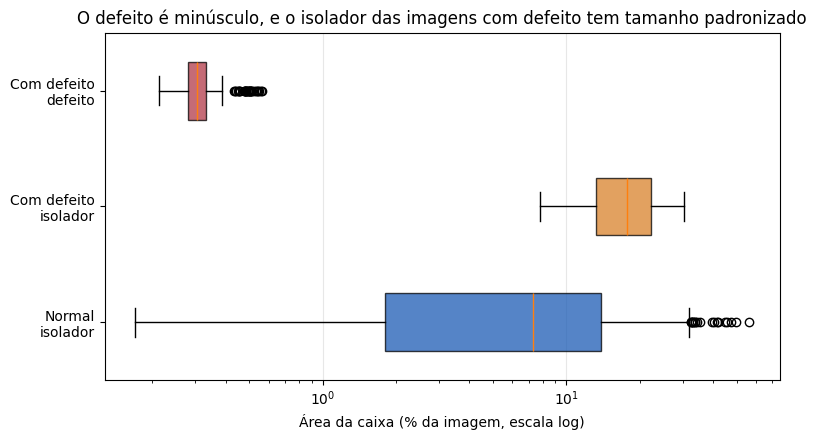

In [15]:
grupos = [
    ("Normal\nisolador", caixas.query("origem == 'Normal_Insulators' and classe == 'insulator'").area_rel, CORES["Normal_Insulators"]),
    ("Com defeito\nisolador", caixas.query("origem == 'Defective_Insulators' and classe == 'insulator'").area_rel, CORES["Defective_Insulators"]),
    ("Com defeito\ndefeito", caixas.query("classe == 'defect'").area_rel, "#b23a48"),
]

fig, ax = plt.subplots(figsize=(8, 4.5))
partes = ax.boxplot([g[1] * 100 for g in grupos], vert=False, patch_artist=True, widths=0.5)
for caixa, (_, _, cor) in zip(partes["boxes"], grupos):
    caixa.set_facecolor(cor)
    caixa.set_alpha(0.75)
ax.set_yticks(range(1, len(grupos) + 1), [g[0] for g in grupos])
ax.set_xscale("log")
ax.set_xlabel("Área da caixa (% da imagem, escala log)")
ax.set_title("O defeito é minúsculo, e o isolador das imagens com defeito tem tamanho padronizado")
ax.grid(axis="x", alpha=0.3)
plt.tight_layout()
Path(RAIZ_PROJETO / "reports" / "fase2").mkdir(parents=True, exist_ok=True)
plt.savefig(RAIZ_PROJETO / "reports" / "fase2" / "g1_area_caixas.png", dpi=150)
plt.show()

## 6. Há caixas inválidas? (pergunta 5)

**Por que importa:** caixas com coordenadas impossíveis quebram o treino ou ensinam errado.

**Hipótese:** nenhuma ou quase nenhuma.

In [16]:
invalidas = caixas[
    (caixas.xmax <= caixas.xmin) | (caixas.ymax <= caixas.ymin) |
    (caixas.xmin < 0) | (caixas.ymin < 0) |
    (caixas.xmax > caixas.largura_img) | (caixas.ymax > caixas.altura_img)
]
print("Caixas inválidas:", len(invalidas))

Caixas inválidas: 0


**O que encontramos (achado 4):** nenhuma caixa inválida em 1.569.

## 7. As imagens das duas origens são diferentes? (pergunta 6, o teste de atalho)

**Por que importa:** se as imagens com defeito diferirem das normais em algo que não é o defeito (tamanho, nitidez, compressão, brilho), o modelo pode aprender essa diferença e "acertar" sem reconhecer o defeito. Isso é um **atalho** (*shortcut learning*).

**Hipótese:** se as imagens com defeito forem sintéticas, terão nitidez, compressão ou brilho diferentes das normais.

Medidas por imagem:

- **brilho:** média dos pixels em tons de cinza;
- **nitidez:** variância do Laplaciano, um filtro que realça bordas (alta = nítida, baixa = borrada);
- **tamanho do arquivo:** imagem com menos detalhe comprime mais e gera um JPEG menor;
- **hash perceptual:** uma "impressão digital" da imagem, usada na seção 8.

Esta célula abre as 848 imagens e pode levar um ou dois minutos.

In [17]:
stats = []
for origem in ORIGENS:
    for caminho in sorted((RAIZ / origem / "images").glob("*.jpg")):
        img = cv2.imread(str(caminho))
        cinza = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
        stats.append({
            "origem": origem,
            "imagem": caminho.name,
            "largura": img.shape[1],
            "altura": img.shape[0],
            "brilho": cinza.mean(),
            "nitidez": cv2.Laplacian(cinza, cv2.CV_64F).var(),
            "tamanho_kb": caminho.stat().st_size / 1024,
            "hash": str(imagehash.phash(Image.open(caminho))),
        })

stats = pd.DataFrame(stats)
print("Resoluções por origem:")
print(stats.groupby("origem")[["largura", "altura"]].value_counts(), "\n")
stats.groupby("origem")[["brilho", "nitidez", "tamanho_kb"]].median()

Resoluções por origem:
origem                largura  altura
Defective_Insulators  1152     864       248
Normal_Insulators     1152     864       600
Name: count, dtype: int64 



,brilho,nitidez,tamanho_kb
origem,,,
Defective_Insulators,152.691109,228.358077,225.93750
Normal_Insulators,130.010384,854.378396,618.48291


**O que encontramos:**

| Medida | Resultado | Achado |
|---|---|---|
| Resolução | Igual nas duas origens (1152 × 864) | 6: descartada como atalho |
| Nitidez | Mediana 228 (com defeito) contra 854 (normal) | 6b |
| Tamanho do arquivo | Mediana 226 KB contra 618 KB | 6b |
| Brilho | Mediana 153 contra 130 | 8 |

### Gráfico 2: nitidez e tamanho do arquivo por origem

Se as duas nuvens de pontos se separarem, uma regra simples, sem olhar para isolador nenhum, distingue as origens.

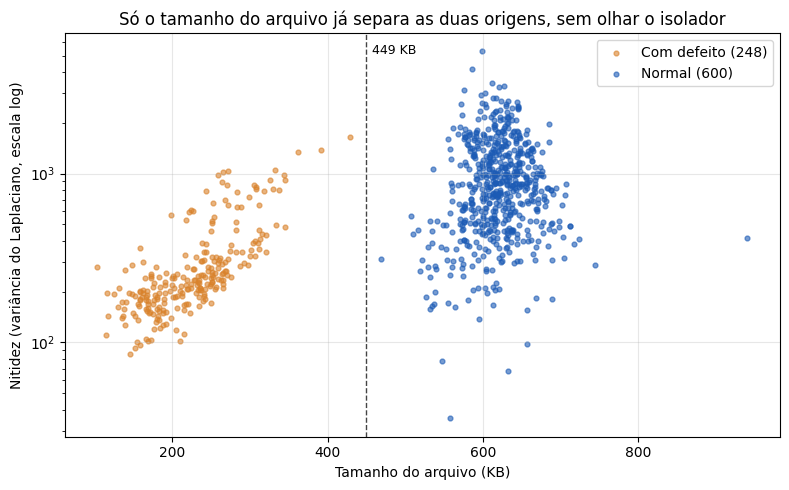

Maior imagem com defeito: 429 KB | menor imagem normal: 469 KB


In [18]:
fig, ax = plt.subplots(figsize=(8, 5))
for origem, grupo in stats.groupby("origem"):
    rotulo = "Com defeito" if origem == "Defective_Insulators" else "Normal"
    ax.scatter(grupo.tamanho_kb, grupo.nitidez, s=12, alpha=0.6, color=CORES[origem], label=f"{rotulo} ({len(grupo)})")

limite = (stats.query("origem == 'Defective_Insulators'").tamanho_kb.max()
          + stats.query("origem == 'Normal_Insulators'").tamanho_kb.min()) / 2
ax.axvline(limite, color="#444", linestyle="--", linewidth=1)
ax.text(limite + 8, ax.get_ylim()[1] * 0.92, f"{limite:.0f} KB", fontsize=9)
ax.set_yscale("log")
ax.set_xlabel("Tamanho do arquivo (KB)")
ax.set_ylabel("Nitidez (variância do Laplaciano, escala log)")
ax.set_title("Só o tamanho do arquivo já separa as duas origens, sem olhar o isolador")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(RAIZ_PROJETO / "reports" / "fase2" / "g2_nitidez_tamanho.png", dpi=150)
plt.show()

maior_defeito = stats.query("origem == 'Defective_Insulators'").tamanho_kb.max()
menor_normal = stats.query("origem == 'Normal_Insulators'").tamanho_kb.min()
print(f"Maior imagem com defeito: {maior_defeito:.0f} KB | menor imagem normal: {menor_normal:.0f} KB")

**O que encontramos (achado 6b, o mais importante da fase):** as duas nuvens não se sobrepõem no eixo do tamanho do arquivo. A maior imagem com defeito (429 KB) é menor que a menor imagem normal (469 KB). Uma regra trivial, "arquivo abaixo de ~450 KB = tem defeito", acerta 100% das imagens.

Consequência: um modelo pode tirar nota alta no teste desta base aprendendo compressão e nitidez em vez do defeito. Tratamento: teste contrafactual na Fase 5 e augmentation de degradação na Fase 7.

## 8. Há imagens duplicadas? (pergunta 7)

**Por que importa:** se a mesma imagem estiver no treino e no teste, o modelo "acerta" uma imagem que já viu, e a métrica fica inflada.

**Hipótese:** algumas duplicatas, talvez entre as imagens com defeito.

O **hash perceptual** reduz a imagem a 64 bits que descrevem a sua aparência geral. Imagens iguais têm o mesmo hash; parecidas, hashes próximos. A distância entre dois hashes (**distância de Hamming**) é o número de bits diferentes: 0 é idêntica, ~32 é o esperado entre duas imagens sem relação.

In [19]:
hashes = [imagehash.hex_to_hash(h) for h in stats["hash"]]

pares = []
for i, j in combinations(range(len(stats)), 2):
    d = hashes[i] - hashes[j]
    if d <= 8:
        pares.append({"img_a": stats.imagem[i], "img_b": stats.imagem[j],
                      "origem_a": stats.origem[i], "origem_b": stats.origem[j], "distancia": d})

pares = pd.DataFrame(pares)
print(len(pares), "pares com distância <= 8")
pares

3 pares com distância <= 8


,img_a,img_b,origem_a,origem_b,distancia
0,0150.jpg,2984.jpg,Normal_Insulators,Normal_Insulators,0
1,0852.jpg,1876.jpg,Normal_Insulators,Normal_Insulators,0
2,1608.jpg,1938.jpg,Normal_Insulators,Normal_Insulators,0


**O que encontramos (achados 7 e 9):**

- 3 pares idênticos (distância 0), todos entre as normais: `0150`/`2984`, `0852`/`1876`, `1608`/`1938`. Uma cópia de cada é removida antes da divisão.
- Nenhuma quase duplicata além desses pares.

**Limite do método:** o hash compara a imagem inteira. Dois recortes diferentes da mesma foto original teriam hashes distantes e passariam despercebidos. A verificação por conteúdo (embeddings) fica para a Fase 3.

## 9. O nome do arquivo indica sequência de voo? (pergunta 8)

**Por que importa:** se imagens com números próximos forem da mesma torre, precisam ficar juntas na divisão treino/teste.

**Hipótese:** se for sequência, vizinhos na numeração serão bem mais parecidos que pares aleatórios.

A semente fixa (`42`) garante que quem rodar de novo obtenha os mesmos pares aleatórios.

In [20]:
normais = stats[stats.origem == "Normal_Insulators"].copy()
normais["num"] = normais.imagem.str.replace(".jpg", "").astype(int)
normais = normais.sort_values("num").reset_index(drop=True)
h = [imagehash.hex_to_hash(x) for x in normais.hash]

vizinhos = [h[i] - h[i + 1] for i in range(len(h) - 1)]
rng = np.random.default_rng(42)
aleatorios = [h[i] - h[j] for i, j in rng.integers(0, len(h), size=(2000, 2)) if i != j]

print("Distância mediana entre vizinhos:", np.median(vizinhos))
print("Distância mediana entre pares aleatórios:", np.median(aleatorios))
print("Vizinhos com distância <= 16:", sum(d <= 16 for d in vizinhos), "de", len(vizinhos))

Distância mediana entre vizinhos: 30.0
Distância mediana entre pares aleatórios: 32.0
Vizinhos com distância <= 16: 0 de 599


**O que encontramos (achado 10):** 30 contra 32, e nenhum vizinho abaixo de 16. A diferença tem a direção esperada, mas é pequena demais para significar "mesma cena". Não há evidência de sequência nos nomes, e portanto não há grupo natural para a divisão da Fase 3.

Lição: uma previsão útil inclui **quanto**, não só a direção.

## 10. Inspeção visual

Números mostram que existe diferença; olhar mostra **qual** é. As três figuras abaixo usam as caixas originais dos XML.

In [ ]:
def desenhar(ax, origem, imagem, recorte=None, titulo=""):
    img = cv2.cvtColor(cv2.imread(str(RAIZ / origem / "images" / imagem)), cv2.COLOR_BGR2RGB)
    ax.imshow(img)
    for _, c in caixas[(caixas.origem == origem) & (caixas.imagem == imagem)].iterrows():
        cor = "#b23a48" if c.classe == "defect" else "#00a6a6"
        ax.add_patch(plt.Rectangle((c.xmin, c.ymin), c.xmax - c.xmin, c.ymax - c.ymin,
                                   fill=False, edgecolor=cor, linewidth=2))
    if recorte:
        x0, y0, x1, y1 = recorte
        ax.set_xlim(x0, x1)
        ax.set_ylim(y1, y0)
    ax.set_title(titulo, fontsize=10)
    ax.axis("off")

# a imagem com defeito de maior área de defeito, para o zoom ficar legível
exemplo = caixas.query("classe == 'defect'").sort_values("area_rel").iloc[-1]
margem = 120
zoom = (exemplo.xmin - margem, exemplo.ymin - margem, exemplo.xmax + margem, exemplo.ymax + margem)
normal_exemplo = caixas_por_imagem.loc["Normal_Insulators"].sort_values().index[-1]

fig, axes = plt.subplots(1, 3, figsize=(16, 4.5))
desenhar(axes[0], "Normal_Insulators", normal_exemplo, titulo=f"Normal ({normal_exemplo}): foto real, vários isoladores")
desenhar(axes[1], "Defective_Insulators", exemplo.imagem, titulo=f"Com defeito ({exemplo.imagem}): um isolador, um defeito")
desenhar(axes[2], "Defective_Insulators", exemplo.imagem, recorte=zoom, titulo="Zoom no defeito: contorno da colagem")
plt.tight_layout()
plt.savefig(RAIZ_PROJETO / "reports" / "fase2" / "g3_exemplos.png", dpi=150)
plt.show()

**O que encontramos:**

- **Achado 13:** as imagens com defeito são **composições**. O isolador foi recortado e colado sobre outra foto, com contorno visível em volta dos discos, e às vezes "flutua" sem estar preso à torre. Isso explica o achado 6b: o objeto colado é nítido, mas o fundo, que ocupa a maior parte da imagem, é enevoado e suave, e a nitidez média sai baixa. Além de nitidez e compressão, o modelo pode aprender **a borda da colagem** em vez do defeito.
- **Achado 12:** há isoladores visíveis sem anotação, em geral cortados na borda da imagem, enquanto em outras imagens objetos cortados foram anotados. A regra de anotação é inconsistente. Se o modelo detectar um desses isoladores, a avaliação contará um FP por um acerto. Tratamento: separar esses "falsos FP" na análise de erros da Fase 6.

A hipótese inicial para as imagens com defeito era "recorte ampliado". Os números eram compatíveis com ela, mas a inspeção visual mostrou que a explicação correta é a colagem.

## 11. Resumo dos achados

| # | Achado | Tratamento |
|---|---|---|
| 1 | 248 defeitos em 1.569 caixas (16%); 29% das imagens | Fase 7: balanceamento |
| 2 | Defeito com 0,31% da área da imagem | Fase 7: tamanho de imagem e tiling |
| 3 | Imagens com defeito: sempre 1 isolador + 1 defeito, isolador de tamanho padronizado | Atalho: controle nas Fases 5 e 7 |
| 4 | Nenhuma caixa inválida | Nada a fazer |
| 5 | Dois XML por imagem com defeito | Conversão junta os dois pelo nome |
| 6 | Resolução igual nas duas origens | Descartada como atalho |
| 6b | Tamanho do arquivo separa as origens 100%; nitidez 3,7x menor | **Limitação principal**: teste contrafactual (Fase 5) e augmentation de degradação (Fase 7) |
| 7 | 3 pares de imagens idênticas | Uma cópia de cada removida: 845 imagens |
| 8 | Imagens com defeito mais claras | Mais uma dimensão do atalho |
| 9 | Sem quase duplicatas pelo hash | Recortes da mesma foto: teste por embeddings na Fase 3 |
| 10 | Nome do arquivo não indica sequência | Sem grupo natural para a divisão |
| 11 | `filename` do XML sem extensão | Nome tirado do arquivo XML; leitura com `dtype=str` |
| 12 | Isoladores na borda sem anotação, de forma inconsistente | Fase 6: separar falsos FP |
| 13 | Imagens com defeito são colagens, com contorno visível | Agrava o atalho; registrar como limitação |